In [1]:
using Fluidum
using PyPlot
include("Libs/plotter.jl");
directory = "Plots/importance_PbPb_276_finer/";
save_plots = false;
# cuts = [0.01, 0.001, 0.0001, 1e-05, 1e-06, 1e-07, 1e-08, 1e-09];
# cuts_string = ["0.01", "0.001", "0.0001", "1e-05", "1e-06", "1e-07", "1e-08", "1e-09"];
no_of_lists = 37;
cuts = 10 .^ range(-1, -10, length=no_of_lists);
no_particles = [4, 4, 6, 7, 9, 20, 26, 44, 53, 82, 116, 164, 204, 251, 305, 355, 409, 468, 507, 541, 569, 589, 607, 616, 621, 629, 633, 637, 637, 637, 638, 639, 640, 641, 641, 641, 641];
#print(cuts);

In [2]:
kernel_folder = "/home/tim/Studium/Masterarbeit/Fluidum/kernels_pce_276_reference/";
kernel_folder_cuts = ["/home/tim/Studium/Masterarbeit/Fluidum/kernels_pce_276_importance_finer/cut_" * string(i) * "/" for i in 1:no_of_lists];
PCE = true

# for folder in kernel_folder_cuts
#     save_all_particles(folder; Tchem=145, Tkin=122, type = "thermal", PCE_bool = PCE)
#     save_all_particles(folder; Tchem=145, Tkin=122, type = "total", PCE_bool = PCE)
# end

# save_all_particles(kernel_folder; Tchem=145, Tkin=122, type = "thermal", PCE_bool = PCE)
# save_all_particles(kernel_folder; Tchem=145, Tkin=122, type = "total", PCE_bool = PCE)

dic = dictionary_pions(kernel_folder);
dic_cuts = [dictionary_pions(folder) for folder in kernel_folder_cuts];

In [3]:
#define a radial grid
rmax = 40;
gridpoints=500;
grid_params = Fluidum.GridParameters(rmax, gridpoints);
disc=CartesianDiscretization(OriginInterval(gridpoints,rmax)) 

#decide the detector to use 
det = :ALICE276;
det_name = detector_dict[det].name; 
dσ_QQdy = detector_dict[det].dσ_QQdy;
σ_in = detector_dict[det].σ_in;

tspan = (0.91477, 20);
norm = 34.487;
rdrop = 8.;
tau0 = tspan[1];

initial_params = Fluidum.InitialParameters(norm, tau0, rdrop);

#take the tabulated data 
ent276 = TabulatedData(string(@__DIR__, "/TabulatedData/EntropyProfile_", det_name, "Duke.txt"));

list = readresonancelist();

┌ Warning: centrality chosen is not a multiple of the bin size. Using 0-4 instead
└ @ Fluidum ~/.julia/dev/Fluidum.jl/src/fluidevo/map_profile.jl:29
sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


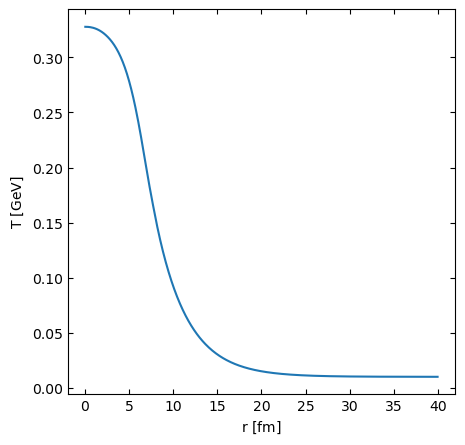

In [4]:
fields = Fluidum.initialize_fields(ent276, 0, 5; grid_params, initial_params);
#print(typeof(fields))
#eos = Heavy_Quark();
eos = FluiduMEoS();

plot_initial_field(fields; save=save_plots, path=directory*"initial_field_pce.png");

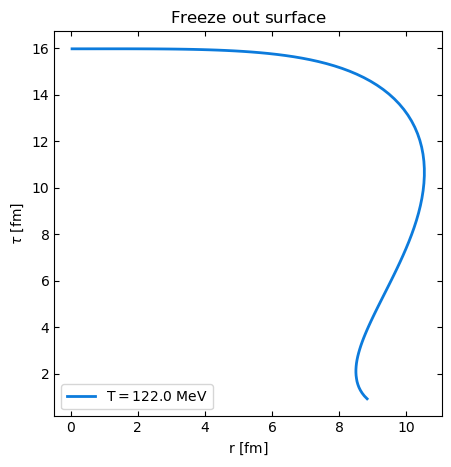

In [5]:
####################################zero diffusion
viscosity = QGPViscosity(2.0874/3.5,0.2); #or, ZeroViscosity();
bulk = SimpleBulkViscosity(0.017963,15.0); #or, ZeroBulkViscosity();

##########################no diffusion
diffusion = ZeroDiffusion();
params=Fluidum.FluidProperties(eos,viscosity,bulk,diffusion);
fo = freeze_out_routine(fields.discrete_field, Fluidum.matrxi1d_visc!_Tscale, params, fields.initial_field, tspan; Tfo = 0.1215);
plot_fo_surface(fo;save=save_plots);

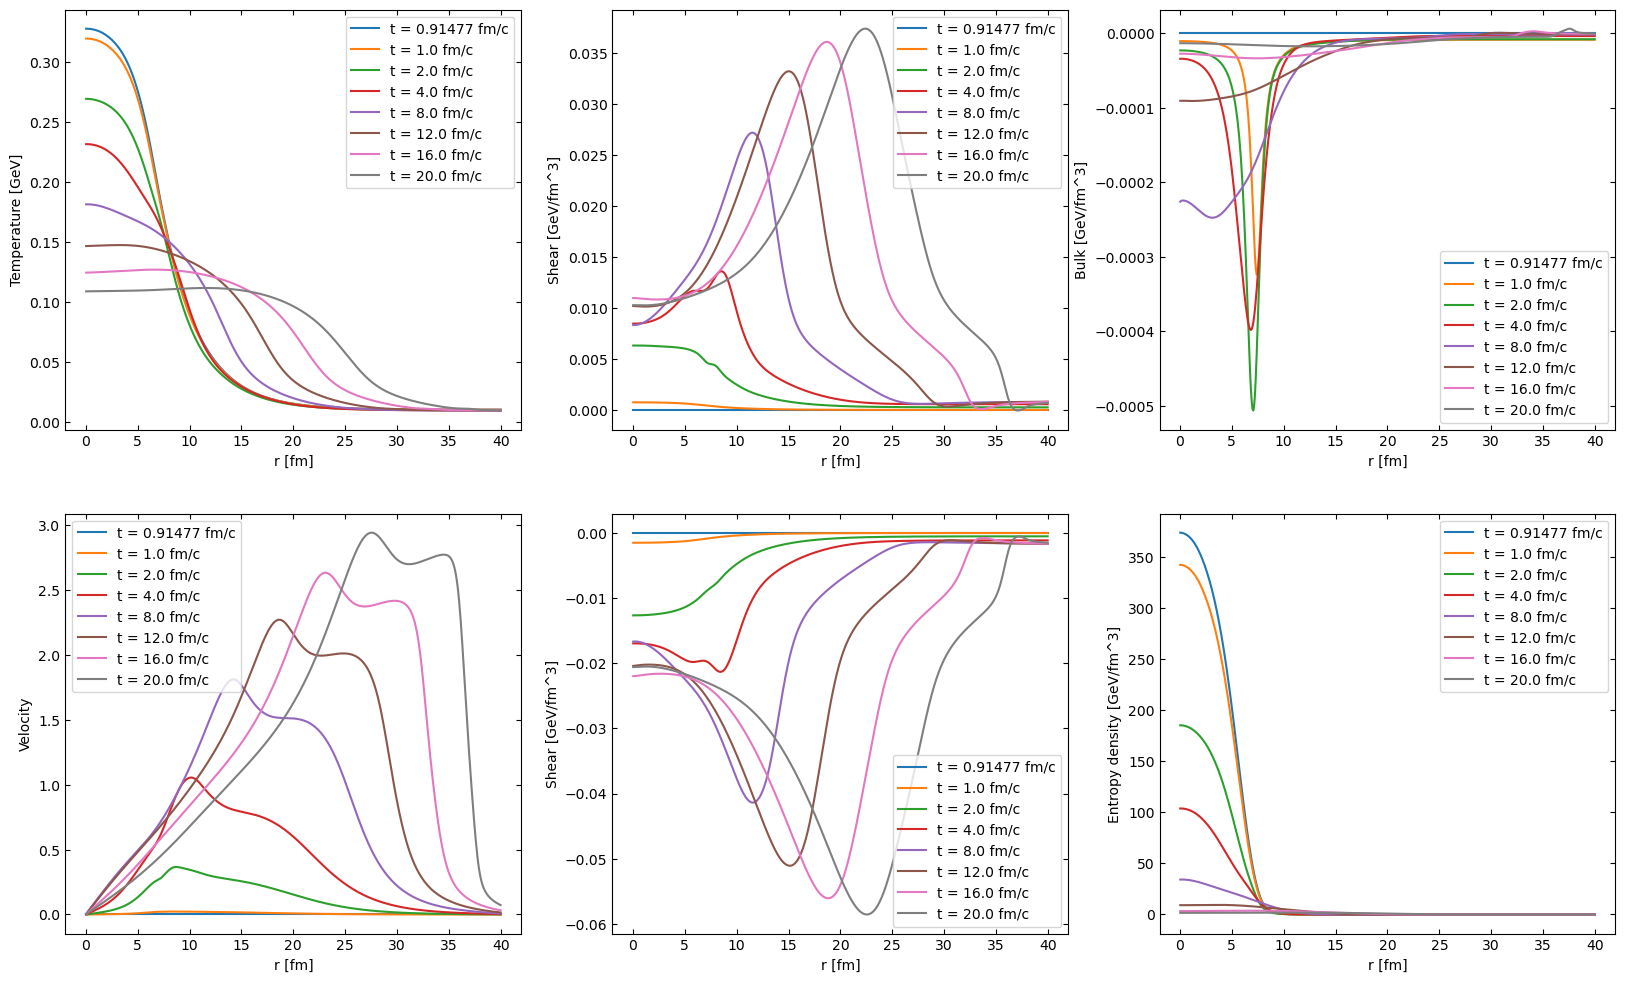

In [6]:
result_field = oneshoot(fields.discrete_field, Fluidum.matrxi1d_visc!, params, fields.initial_field, tspan; reltol = 1e-8);

times = [tspan[1], 1.0, 2.0, 4.0, 8.0, 12.0, 16.0, tspan[2]]
radius = zeros(gridpoints+2)
[radius[i]= disc.grid[i][1] for i in eachindex(disc.grid[1:end])] 

plot_result_fields(result_field, radius, times, params; save=save_plots);

Here begins my own plotting routine

In [7]:
include("Libs/data_lib.jl");

extraction_end_pion = 41; #number of data points to extract
filename_pion = "ExperimentalData/HEPData-ins1222333-v1-Table_1.csv"

data_pion = get_data(filename_pion, extraction_end_pion);
mult_pion_data = calculate_yield(data_pion; verbose=true);
mult_pion_data_excess = calculate_yield(data_pion; excess=true);
println("Pion data multiplicity (0.1 - 3.0 GeV/c): ", mult_pion_data[1], " +- ", mult_pion_data[2])
println("Pion data multiplicity (0.1 - 0.5 GeV/c): ", mult_pion_data_excess[1], " +- ", mult_pion_data_excess[2])

Yield: 682.1370916347523 + 2.486344390645263 (stat) - -2.486344390645263 (stat) + 51.43014311075346 (syst) - -51.43014311075346 (syst)
Yield: 682.1370916347523 ± 51.49020808679525 (total) + 51.49020808679525 (total) - 51.49020808679525 (total)
Pion data multiplicity (0.1 - 3.0 GeV/c): 682.1370916347523 +- 51.49020808679525
Pion data multiplicity (0.1 - 0.5 GeV/c): 397.03432248104536 +- 35.687740914279544


In [8]:
include("Libs/results_lib.jl");

#@show dic.pion
use_3d_kernel = false

results_pion = get_results(fo, dic.pion, params, data_pion.pt; interpolate_3d=use_3d_kernel);
results_pion_cuts = get_results_list(fo, dic_cuts, params, data_pion.pt; interpolate_3d=use_3d_kernel);

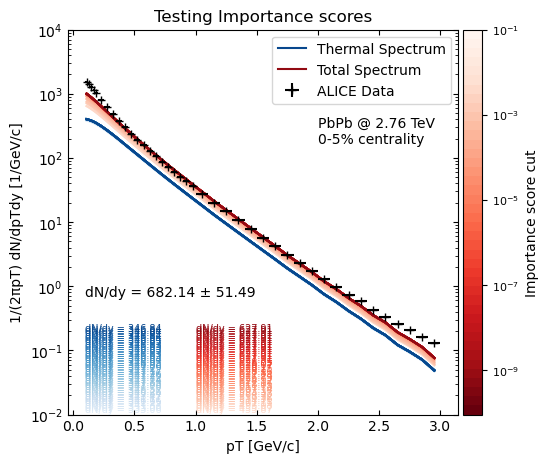

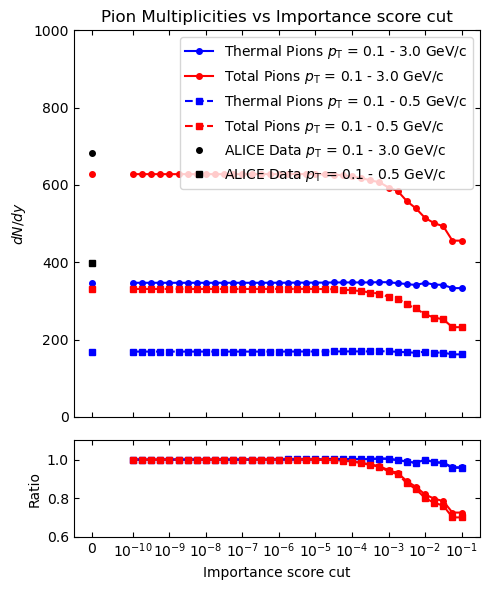

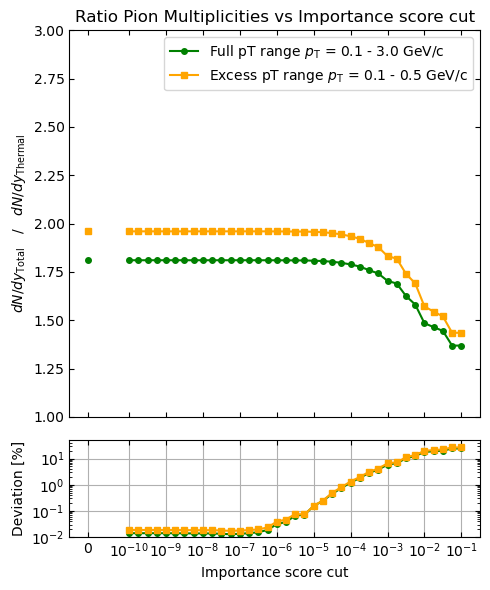

In [9]:
include("Libs/plotter_importance.jl");

plot_importance_spectra(results_pion_cuts, data_pion, mult_pion_data, cuts; save=save_plots)
plot_importance_mults(results_pion, results_pion_cuts, mult_pion_data, mult_pion_data_excess, cuts; save=save_plots)
plot_importance_ratios(results_pion, results_pion_cuts, cuts; save=save_plots)

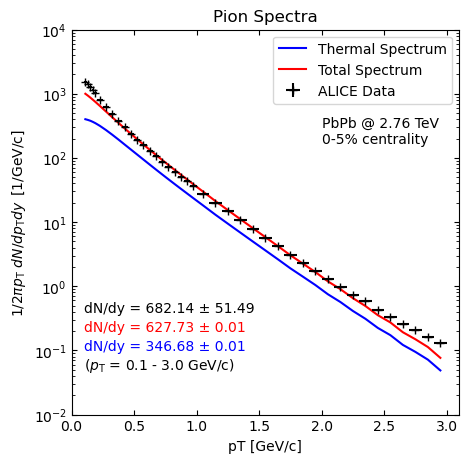

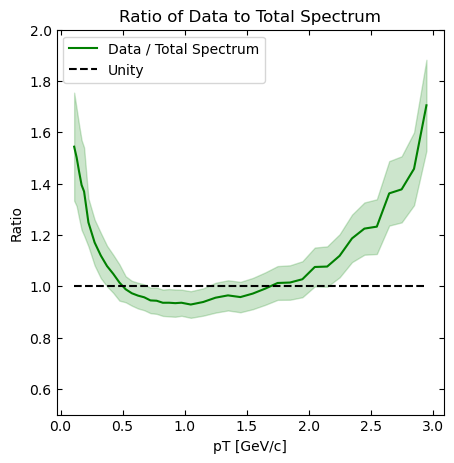

In [10]:
plot_spectra(results_pion, data_pion, mult_pion_data; save=save_plots)
plot_ratio(results_pion, data_pion; save = save_plots)

In [11]:
excess, excess_err_exp, excess_err_mod = calculate_excess(results_pion, mult_pion_data_excess)

println("Pion excess multiplicity (0.1 - 0.5 GeV/c) for 0-5% centrality: ", excess, " +- ", excess_err_exp, " (exp) +- ", excess_err_mod, " (model)")

Pion excess multiplicity (0.1 - 0.5 GeV/c) for 0-5% centrality: 66.22433719143106 +- 35.687740914279544 (exp) +- 0.004926823592443882 (model)


## Test smaller lists for reference

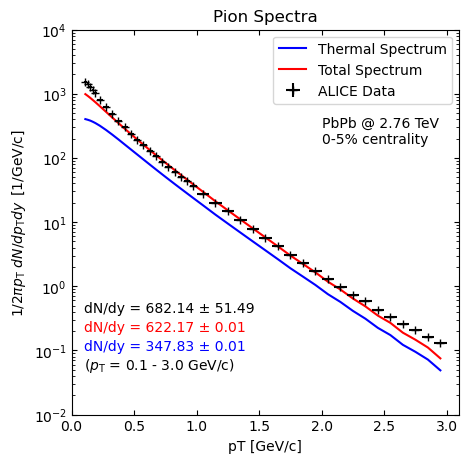

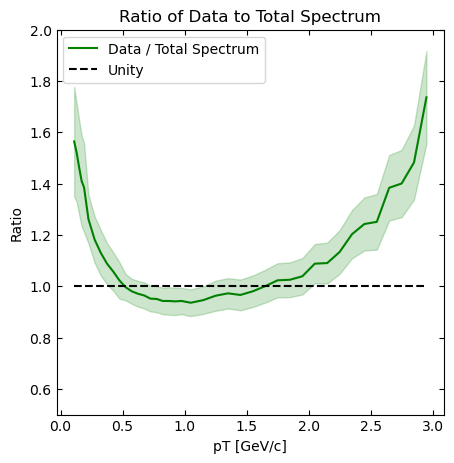

In [12]:
index = 13    # 13 : 10-4    17 : 10-5

test_reference = get_results_from_list_helper(results_pion_cuts, index)

plot_spectra(test_reference, data_pion, mult_pion_data; save=save_plots)
plot_ratio(test_reference, data_pion; save = save_plots)